# 01 · Weekly forecast (ridge regression, trained on real OULAD data)

**In the app:** the Home card shows *"Forecast: ~18h 30m by Sunday · on track"*.

**Task:** at the end of day *d* of a week, predict the activity still to come before the week ends.
The forecast is `so_far + max(0, ŷ_remaining)`, so it can never fall below what's already logged.

**Features** (with `left = 1 − (d+1)/7`):

| feature | definition |
|---|---|
| `f_hist` | left · (mean daily activity over the 14 days before this week) · 7 |
| `f_last` | left · last week's total |
| `f_pace` | left · so_far / ((d+1)/7) — the current pace extrapolated |

**Why the weights transfer from clicks to minutes:** every feature is linear in the activity unit, and there's no intercept. If
all activity is multiplied by a constant *c* (clicks → minutes), every feature and the target scale by *c*, so the least-squares
weights stay the same. This is also why the user's weekly goal isn't a feature: OULAD has no goals.

**Personalisation (on device):** once a user has enough complete weeks (chosen below from the evidence), the app refits
$w = (X^TX + \lambda I)^{-1}(X^Ty + \lambda w_0)$, a ridge regression shrunk towards these global weights $w_0$.

In [1]:
import json, pathlib, hashlib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

DATA = pathlib.Path('data')
PROC = DATA / 'processed'
ASSETS = pathlib.Path('../app/src/main/assets/ml')
ASSETS.mkdir(parents=True, exist_ok=True)
RED, INK, GREY, LINE = '#E11D2A', '#111111', '#8C8C8C', '#DEDEDE'

def is_test(student_id):
    """Deterministic 20% hold-out split by student (no student appears in both sets)."""
    return int(hashlib.md5(str(student_id).encode()).hexdigest(), 16) % 5 == 0

In [2]:
enr = pd.read_parquet(PROC / 'enrolments.parquet')
daily = pd.read_parquet(PROC / 'daily_enrolment.parquet')
FEATURES = ['f_hist', 'f_last', 'f_pace']

def rows_for(eid, n_days, g):
    T = np.zeros(n_days, dtype=float)
    T[g.date.to_numpy()] = g.clicks.to_numpy()
    out = []
    for w in range(2, n_days // 7):
        week = T[w*7:(w+1)*7]
        avg14, last = T[w*7-14:w*7].mean(), T[(w-1)*7:w*7].sum()
        cs = np.cumsum(week)
        for d in range(7):
            frac = (d + 1) / 7; left = 1 - frac
            out.append((eid, w, d, cs[d], cs[-1], left*avg14*7, left*last, left*cs[d]/frac))
    return out

nd = enr.set_index('enrolment_id').n_days
recs = [r for eid, g in daily.groupby('enrolment_id') for r in rows_for(eid, int(nd[eid]), g)]
df = pd.DataFrame(recs, columns=['enrolment_id', 'week', 'day', 'so_far', 'total'] + FEATURES)
df['remaining'] = df.total - df.so_far
df = df.merge(enr[['enrolment_id', 'id_student']], on='enrolment_id')
df['test'] = df.id_student.map(is_test)
train, test = df[~df.test], df[df.test]
print(f'{len(df):,} rows | train {len(train):,} | test {len(test):,} | '
      f'{df.id_student.nunique():,} students')

4,810,379 rows | train 3,825,514 | test 984,865 | 19,785 students


## Fit
Closed-form ridge regression. λ is chosen on a validation split carved out of the **training** students. The test students are
only used once, for the final numbers.

In [3]:
def ridge(X, y, lam, w0=None):
    w0 = np.zeros(X.shape[1]) if w0 is None else w0
    lam = lam + 1e-9  # numerical floor: an all-zero week would otherwise make X'X singular
    return np.linalg.solve(X.T @ X + lam * np.eye(X.shape[1]), X.T @ y + lam * w0)

def mae_total(frame, w):
    return np.abs(frame.so_far + np.maximum(frame[FEATURES].to_numpy() @ w, 0) - frame.total).mean()

val_mask = train.id_student % 7 == 0
tr, va = train[~val_mask], train[val_mask]
lams = [0, 1e2, 1e4, 1e6, 1e8]
val = {lam: mae_total(va, ridge(tr[FEATURES].to_numpy(), tr.remaining.to_numpy(), lam)) for lam in lams}
LAM = min(val, key=val.get)
W = ridge(train[FEATURES].to_numpy(), train.remaining.to_numpy(), LAM)
print('validation MAE by lambda:', {k: round(v, 2) for k, v in val.items()})
print('chosen lambda', LAM, '| weights', dict(zip(FEATURES, W.round(4))))

validation MAE by lambda: {0: np.float64(15.62), 100.0: np.float64(15.62), 10000.0: np.float64(15.62), 1000000.0: np.float64(15.62), 100000000.0: np.float64(15.57)}
chosen lambda 100000000.0 | weights {'f_hist': np.float64(0.4242), 'f_last': np.float64(0.1051), 'f_pace': np.float64(0.1737)}


## Held-out evaluation vs baselines
* **pace:** assume the rest of the week continues at this week's pace (what most trackers show).
* **last week:** assume the week ends at last week's total (but never below what's already logged).

Error is reported relative to the size of the week (`MAE / mean weekly total`), so it reads the same in clicks or minutes.

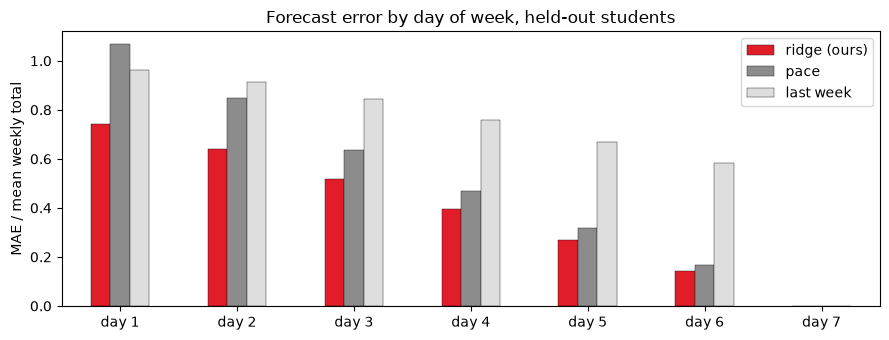

{'ridge (ours)': '38.6%', 'pace': '50.0%', 'last week': '67.6%'}


,ridge (ours),pace,last week
day 1,0.740,1.067,0.964
day 2,0.641,0.848,0.913
day 3,0.517,0.636,0.843
day 4,0.394,0.467,0.760
day 5,0.270,0.317,0.669
day 6,0.143,0.167,0.585
day 7,0.000,0.000,0.000


In [4]:
def predictions(f):
    frac = (f.day + 1) / 7
    return {
        'ridge (ours)': f.so_far + np.maximum(f[FEATURES].to_numpy() @ W, 0),
        'pace': f.so_far / frac,
        'last week': np.maximum(f.so_far, f.f_last / (1 - frac).where(frac < 1, 1)),
    }
scale = test.groupby(['enrolment_id', 'week']).total.first().mean()
rel = pd.DataFrame({k: (v - test.total).abs().groupby(test.day).mean() / scale
                    for k, v in predictions(test).items()})
rel.index = [f'day {d+1}' for d in rel.index]
ax = rel.plot(kind='bar', figsize=(9, 3.5), color=[RED, GREY, LINE], rot=0, edgecolor=INK, linewidth=.3)
ax.set_ylabel('MAE / mean weekly total'); ax.set_title('Forecast error by day of week, held-out students')
plt.tight_layout(); plt.show()
overall = {k: float((v - test.total).abs().mean() / scale) for k, v in predictions(test).items()}
print({k: f'{v:.1%}' for k, v in overall.items()})
rel.round(3)

## Does personalisation help?
For each held-out enrolment: fit on its first *k* weeks, then test on its remaining weeks. We compare the global prior, a purely
personal fit, and the personal fit shrunk towards the prior.

In [5]:
def personal_curve(frame, w_prior, ks, lam_p, max_enrol=1500):
    res = {}
    groups = list(frame.groupby('enrolment_id'))[:max_enrol]
    for k in ks:
        acc = {'global prior': [], 'personal only': [], 'personal + prior': []}
        for _, g in groups:
            a, b = g[g.week < 2 + k], g[g.week >= 2 + k]
            if len(b) == 0: continue
            Xa, ya = a[FEATURES].to_numpy(), a.remaining.to_numpy()
            s = b.groupby('week').total.first().mean() or 1
            for name, w in [('global prior', w_prior), ('personal only', ridge(Xa, ya, 1e-6 * (Xa**2).sum())),
                            ('personal + prior', ridge(Xa, ya, lam_p * (Xa**2).sum() / len(Xa), w_prior))]:
                acc[name].append(mae_total(b, w) / s)
        res[k] = {n: np.median(v) for n, v in acc.items()}
    return pd.DataFrame(res).T

# All choices here are made on VALIDATION students (va), with a prior fitted only on the other training
# students (tr). The test students are used once, afterwards, to report the result.
W_tr = ridge(tr[FEATURES].to_numpy(), tr.remaining.to_numpy(), LAM)
# lambda is scaled by the user's own feature magnitude, so it is unit-free on the phone as well
cands = [1, 3, 10, 30, 100]
cv = {c: personal_curve(va, W_tr, [6], c, 800).loc[6, 'personal + prior'] for c in cands}
LAM_P = min(cv, key=cv.get)
print('validation relative-MAE by lambda_personal:', {k: round(v, 4) for k, v in cv.items()}, '-> chosen', LAM_P)
val_curve = personal_curve(va, W_tr, [3, 6, 10, 15], LAM_P, 800)
print('validation curve'); print(val_curve.round(4))


validation relative-MAE by lambda_personal: {1: np.float64(0.4803), 3: np.float64(0.4725), 10: np.float64(0.4726), 30: np.float64(0.4683), 100: np.float64(0.4665)} -> chosen 100


validation curve
    global prior  personal only  personal + prior
3         0.4533         0.5230            0.4526
6         0.4661         0.4973            0.4665
10        0.4589         0.4674            0.4534
15        0.4628         0.4623            0.4537


personalise from 3 weeks of history


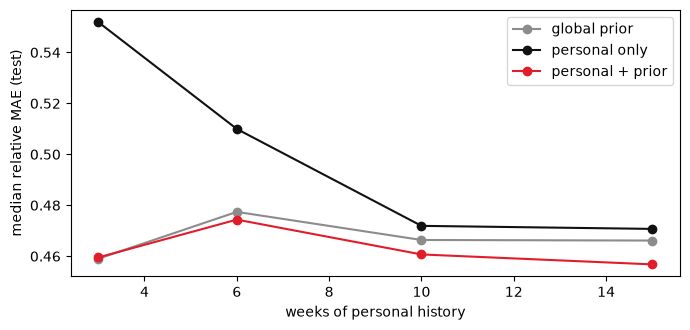

,global prior,personal only,personal + prior
3,0.4590,0.5519,0.4595
6,0.4774,0.5100,0.4744
10,0.4664,0.4719,0.4607
15,0.4662,0.4707,0.4568


In [6]:
# Switch personalisation on only from the amount of history where it beats the prior ON VALIDATION.
better = val_curve.index[val_curve['personal + prior'] < val_curve['global prior']]
MIN_WEEKS = int(better.min()) if len(better) else 9999
print('personalise from', MIN_WEEKS, 'weeks of history' if MIN_WEEKS < 9999 else '(never: prior is always better)')
# Final, one-time report on the held-out test students:
curve = personal_curve(test, W, [3, 6, 10, 15], LAM_P)
ax = curve.plot(marker='o', figsize=(7, 3.4), color=[GREY, INK, RED])
ax.set_xlabel('weeks of personal history'); ax.set_ylabel('median relative MAE (test)'); plt.tight_layout(); plt.show()
curve.round(4)

## Export → `app/src/main/assets/ml/weekly_forecast.json`
Read by `WeeklyForecaster.kt`. The personal λ is multiplied on device by `mean(x²)` of the user's own design matrix, matching
the scaling used above.

In [7]:
export = {
    'version': 2, 'source': 'OULAD (CC-BY 4.0), held-out by student',
    'features': FEATURES, 'weights': [float(x) for x in W],
    'lambda_personal_rel': float(LAM_P), 'min_personal_weeks': MIN_WEEKS,
    'test_relative_mae': overall['ridge (ours)'],
    'baseline_relative_mae': {k: v for k, v in overall.items() if k != 'ridge (ours)'},
}
(ASSETS / 'weekly_forecast.json').write_text(json.dumps(export, indent=2))
export

{'version': 2,
 'source': 'OULAD (CC-BY 4.0), held-out by student',
 'features': ['f_hist', 'f_last', 'f_pace'],
 'weights': [0.42418492914215533, 0.10506852145322801, 0.17374700768826792],
 'lambda_personal_rel': 100.0,
 'min_personal_weeks': 3,
 'test_relative_mae': 0.3864201420489571,
 'baseline_relative_mae': {'pace': 0.5003671950628023,
  'last week': 0.6762411462835775}}

## Limitations
* Trained on Open University distance-learning students in 2013–14. Their weekly rhythm (assignment cycles) may differ from a
  school or university student using Milestone. That's why the app personalises once it has data.
* Clicks are only a proxy for study time. The scale-invariance argument covers the *unit*, not the fact that clicks and
  minutes measure slightly different behaviour.
* Personalisation gains are **small**. The switch-on threshold was picked on validation students. On the test students it is
  essentially neutral at the threshold (within about 0.1% of the prior) and gives a small improvement with more weeks of
  history (see the test curve above). It's a modest refinement, not a big win.
* The model is trained on rows taken at the *end* of a day. The app therefore computes features as of the end of yesterday,
  adds today's minutes, and shows no forecast until 14 days of history exist.